In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.axes._axes import _log as matplotlib_axes_logger
from mpl_toolkits import mplot3d
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from matplotlib.colors import ListedColormap

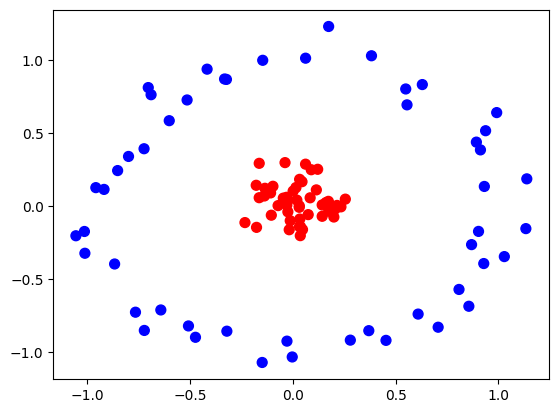

In [3]:
from sklearn.datasets import make_circles

X, y = make_circles(n_samples=100, factor=0.1, noise=0.1)

plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='bwr')

plt.show()

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.20)

In [5]:
classifier = SVC(kernel="linear")
classifier.fit(X_train, y_train.ravel())
y_pred = classifier.predict(X_test)

In [6]:
from sklearn.metrics import accuracy_score
accuracy_score(y_test, y_pred)

0.5

In [7]:
zero_one_colourmap = ListedColormap(('blue', 'red'))
def plot_decision_boundary(X, y, clf):
    X_set, y_set = X, y
    X1, X2 = np.meshgrid(np.arange(start = X_set[:, 0].min() - 1, 
                                 stop = X_set[:, 0].max() + 1, 
                                 step = 0.01),
                       np.arange(start = X_set[:, 1].min() - 1, 
                                 stop = X_set[:, 1].max() + 1, 
                                 step = 0.01))
  
    plt.contourf(X1, X2, clf.predict(np.array([X1.ravel(), 
                                             X2.ravel()]).T).reshape(X1.shape),
               alpha = 0.75, 
               cmap = zero_one_colourmap)
    plt.xlim(X1.min(), X1.max())
    plt.ylim(X2.min(), X2.max())
    for i, j in enumerate(np.unique(y_set)):
        plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1],
                c = (zero_one_colourmap)(i), label = j)
    plt.title('SVM Decision Boundary')
    plt.xlabel('X1')
    plt.ylabel('X2')
    plt.legend()
    return plt.show()

C:\Users\bilal\AppData\Local\Temp\ipykernel_7272\3603277588.py:18: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1],


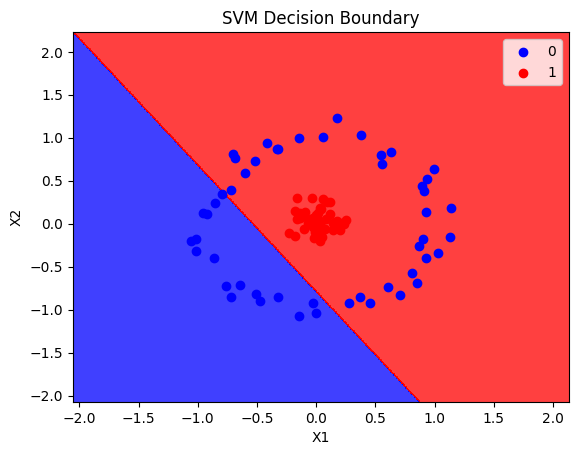

In [8]:
plot_decision_boundary(X, y, classifier)

In [9]:
def plot_3d_plot(X, y):
    r = np.exp(-(X ** 2).sum(1))
    ax = plt.subplot(projection='3d')
    ax.scatter3D(X[:, 0], X[:, 1], r, c=y, s=100, cmap='bwr')
    ax.set_xlabel('X1')
    ax.set_ylabel('X2')
    ax.set_zlabel('y')
    return ax

<Axes3D: xlabel='X1', ylabel='X2', zlabel='y'>

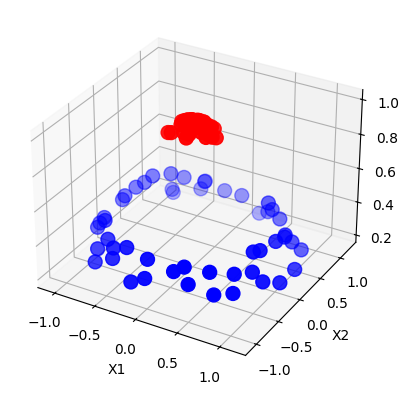

In [10]:
plot_3d_plot(X,y)

In [11]:
rbf_classifier = SVC(kernel="rbf")
rbf_classifier.fit(X_train, y_train)
y_pred = rbf_classifier.predict(X_test)

In [12]:
accuracy_score(y_test, y_pred)

1.0

C:\Users\bilal\AppData\Local\Temp\ipykernel_7272\3603277588.py:18: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1],


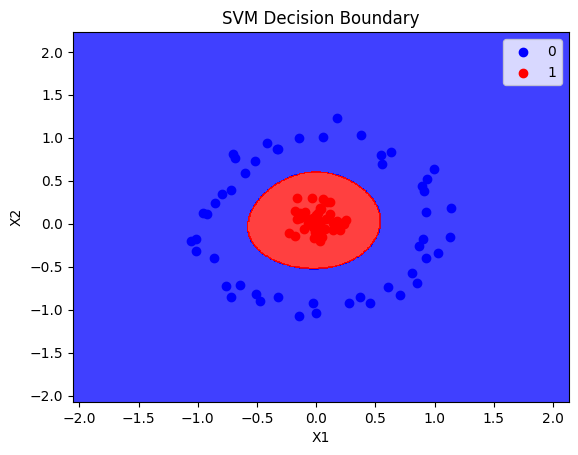

In [13]:
plot_decision_boundary(X, y, rbf_classifier)

In [14]:
poly_classifier = SVC(kernel="poly",degree=2)
poly_classifier.fit(X_train, y_train)
y_pred = poly_classifier.predict(X_test)

In [15]:
accuracy_score(y_test, y_pred)

1.0

C:\Users\bilal\AppData\Local\Temp\ipykernel_7272\3603277588.py:18: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1],


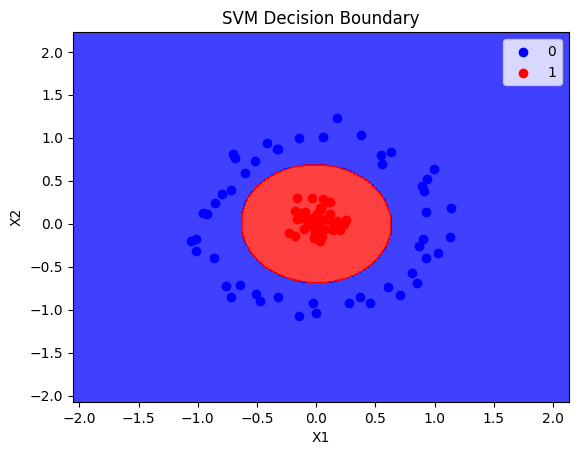

In [16]:
plot_decision_boundary(X, y, poly_classifier)

In [17]:
X

array([[-0.03784788,  0.29824801],
       [-0.03693208,  0.04450956],
       [ 0.0324518 , -0.14048301],
       [-0.23276485, -0.11260852],
       [ 0.93743657,  0.51680936],
       [ 0.01968803,  0.041283  ],
       [-0.02420485,  0.03939564],
       [ 0.01514286,  0.12724624],
       [-0.13553899,  0.12239064],
       [-1.01105472, -0.32279237],
       [-0.72200849, -0.85167398],
       [ 1.02853064, -0.34569061],
       [ 0.36952665, -0.85322067],
       [ 0.16088293,  0.02427341],
       [-0.51406768,  0.72755706],
       [ 0.19956985, -0.07451446],
       [ 0.03305906,  0.18362043],
       [ 0.91241157,  0.38544088],
       [ 1.13322202, -0.15399851],
       [ 0.03161875,  0.00154901],
       [-0.79885294,  0.34056065],
       [-0.33186824,  0.8712136 ],
       [ 0.25535224,  0.0479403 ],
       [ 0.17476802, -0.03478439],
       [-0.32068477, -0.85675634],
       [ 0.20566503, -0.01979473],
       [-0.70294296,  0.81247022],
       [ 0.0747855 , -0.05809983],
       [ 0.70670124,

In [18]:
np.exp(-(X**2)).sum(1)

array([1.91345816, 1.99665781, 1.97940543, 1.93466147, 1.18088891,
       1.99790962, 1.99786348, 1.98370949, 1.96692906, 1.26084077,
       1.07790618, 1.23455495, 1.35524352, 1.97385976, 1.35676361,
       1.95541757, 1.9657533 , 1.29690702, 1.25343763, 1.99899835,
       1.418752  , 1.36384002, 1.93457997, 1.96870867, 1.3822426 ,
       1.95819223, 1.12689779, 1.99105284, 1.10934385, 1.97389012,
       1.40666613, 1.97028731, 1.29552331, 1.97465892, 1.35517948,
       1.18978073, 1.42633535, 1.34368031, 1.98967217, 1.35238441,
       1.14666176, 1.99596822, 1.97501068, 1.99484989, 1.93166889,
       1.94859223, 1.28836618, 1.92369987, 1.24529607, 1.99910843,
       1.3539691 , 1.99486177, 1.97885379, 1.32844124, 1.27896953,
       1.99541573, 1.97231493, 1.23964089, 1.94844895, 1.99897792,
       1.98021185, 1.40202154, 1.2827811 , 1.97975   , 1.24359596,
       1.40257438, 1.99791153, 1.94669066, 1.38360229, 1.98941499,
       1.17222818, 1.95473095, 1.42424976, 1.41289964, 1.97624

In [19]:
X_new=np.exp(-(X**2))

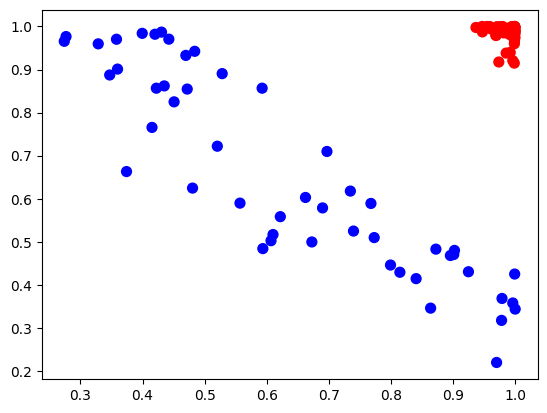

In [20]:
plt.scatter(X_new[:, 0], X_new[:, 1], c=y, s=50, cmap='bwr')